# CNN và ResNet

CNN (convolutional neural network) xếp nhiều lớp convolution nối nhau: lớp đầu dò nét, các lớp sau ghép nét thành hình phức tạp hơn, cuối cùng ra một nhãn cho cả ảnh. Nhưng thêm lớp không phải lúc nào cũng tốt hơn: mạng quá sâu có thể học kém hơn mạng nông. ResNet sửa việc này bằng đường đi tắt (skip connection), cộng thẳng đầu vào của một khối vào đầu ra của nó. Bài này xây một CNN nhỏ, so một mạng 18 lớp có và không có đường đi tắt, rồi đọc cấu trúc ResNet-18 và ResNet-50.

> **Mục tiêu**
>
> - Theo dõi shape từ ảnh tới đầu ra của CNN.
> - Huấn luyện một CNN nhỏ.
> - Viết residual block; hiểu vì sao đường đi tắt giúp mạng sâu học được.
> - Đọc cấu trúc ResNet và đếm tham số.

## Từ nét đến nhãn

CNN (convolutional neural network) dùng convolution để tạo feature map, rồi activation như ReLU để ghép các đặc trưng một cách phi tuyến. Thiếu activation, hai convolution liên tiếp vẫn chỉ là một phép affine của ảnh đầu vào (không padding thì đúng bằng một convolution $5\times5$), nên xếp thêm lớp không tạo được ranh giới quyết định phức tạp hơn.



CNN nhỏ ở đây dùng conv $1\to8$, ReLU, max pooling, rồi conv $8\to8$, ReLU. Global average pooling lấy trung bình mỗi feature map thành một số. Tám số đi vào linear head để tạo hai logits. Logit là điểm chưa chuẩn hóa, không phải xác suất; `CrossEntropyLoss` nhận trực tiếp chúng.

| Bước | Shape với ảnh xám $12\times12$ |
|---|---|
| Ảnh đầu vào | `(N, 1, 12, 12)` |
| Conv 3, padding 1, ReLU | `(N, 8, 12, 12)` |
| MaxPool 2 | `(N, 8, 6, 6)` |
| Conv 3, padding 1, ReLU | `(N, 8, 6, 6)` |
| Global average pooling | `(N, 8)` |
| Linear head | `(N, 2)` |

Trung bình toàn ảnh khiến head không cần một trọng số riêng cho từng vị trí, và head luôn nhận đúng 8 số dù ảnh vào lớn hay nhỏ; còn nếu `flatten` cả feature map thì số đặc trưng đổi theo kích thước ảnh. Global max pooling lấy giá trị lớn nhất thay cho trung bình: nó trả lời “có chỗ nào khớp mẫu không”, còn trung bình đo “khớp nhiều đến đâu trên cả ảnh”. Đổi lại, cả hai làm head mất phần lớn thông tin tọa độ. Với câu hỏi “nét đứng hay ngang”, lựa chọn này hợp lý; với câu hỏi “nét nằm bên trái hay phải”, phải giữ hoặc bổ sung thông tin vị trí. Nhờ global pooling, đặc trưng cuối $512 \times 7 \times 7$ chỉ còn 512 số, nên head 10 lớp có $512 \cdot 10 + 10 = 5130$ tham số.

**Hỏi nhanh.** Head trả về logits `(N, 2)`. Nhãn đưa vào `CrossEntropyLoss` cùng logits ấy phải có shape và kiểu gì?

- A. `(N, 2)`, one-hot kiểu `torch.long`
- B. `(N, 1)`, float chứa 0.0 hoặc 1.0
- C. `(N,)`, kiểu `torch.long`, chứa chỉ số lớp
- D. `(N, 1, 12, 12)`, mask nhị phân theo từng pixel

<details><summary>Đáp án</summary>

C. `(N,)`, kiểu `torch.long`, chứa chỉ số lớp

Mỗi ảnh có một chỉ số lớp là 0 hoặc 1, nên nhãn là vector `(N,)` kiểu long. One-hot kiểu long sẽ báo lỗi, vì `CrossEntropyLoss` chỉ nhận target `(N, 2)` khi đó là xác suất kiểu float. `(N, 1)` float là target của `BCEWithLogitsLoss` với một logit; đưa vào `CrossEntropyLoss` thì báo lỗi “multi-target not supported”. Mask theo pixel là target của bài toán phân đoạn (bài 5.6).

</details>

## Một bộ dữ liệu biết rõ quy tắc

Ta tự sinh ảnh nét đứng và ngang dài 8 ô, rộng 2 ô, đặt ở một vị trí ngẫu nhiên rồi thêm nhiễu nhỏ. Mỗi ảnh chỉ có một nét, hai lớp xuất hiện cân bằng. Vì biết chính xác quy tắc sinh, ta biết model phải học được gì: nếu model không học nổi, nghi ngờ đầu tiên là cấu trúc hay vòng train, không phải dữ liệu.

Hàm dưới đặt nét tránh sát biên. `seed` của train và validation khác nhau để hai tập không dùng chung dãy nhiễu. Với ảnh thật, mọi ảnh của cùng một học sinh hay cùng một buổi chụp phải nằm cùng một phía của split, như group split ở bài 1.3.

In [ ]:
import numpy as np
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(52)

def make_lines(count, seed):
    rng = np.random.default_rng(seed)
    images = np.zeros((count, 1, 12, 12), dtype=np.float32)
    labels = np.arange(count) % 2
    for index, label in enumerate(labels):
        position = int(rng.integers(3, 8))
        if label == 0:
            images[index, 0, 2:10, position:position + 2] = 1.0
        else:
            images[index, 0, position:position + 2, 2:10] = 1.0
    images += rng.normal(0, 0.04, images.shape).astype(np.float32)
    images = np.clip(images, 0, 1)
    return torch.from_numpy(images), torch.tensor(labels, dtype=torch.long)

train_images, train_labels = make_lines(80, 1)
valid_images, valid_labels = make_lines(40, 2)
print(tuple(train_images.shape), torch.bincount(train_labels).tolist())
print(tuple(valid_images.shape), torch.bincount(valid_labels).tolist())

(80, 1, 12, 12) [40, 40]
(40, 1, 12, 12) [20, 20]


Ta kiểm cả shape và số ảnh mỗi lớp trước khi train. Hai lớp cân bằng nên đoán một lớp cố định đã được accuracy 0.5; model phải vượt mức đó trên validation mới chứng tỏ học được tín hiệu.



**Hỏi nhanh.** `make_lines` chọn vị trí nét bằng `rng.integers(3, 8)`. Bỏ nhiễu đi thì có bao nhiêu ảnh sạch khác nhau, và validation kiểm được điều gì?

- A. 5 ảnh, validation kiểm cả vị trí lẫn hướng nét mới
- B. 10 ảnh, validation chỉ khác train ở phần nhiễu
- C. 10 ảnh, validation có những vị trí mà train chưa gặp
- D. 80 ảnh, vì mỗi ảnh train là một mẫu riêng

<details><summary>Đáp án</summary>

B. 10 ảnh, validation chỉ khác train ở phần nhiễu

`integers(3, 8)` cho 5 vị trí, từ 3 đến 7, không gồm 8. Nhân với hai hướng là 10 ảnh sạch, và cả 10 ảnh đều có mặt ở cả train lẫn validation. Vì vậy validation đo khả năng chịu một chút nhiễu, không đo khả năng nhận ra nét ở vị trí hay độ dài chưa gặp. 5 là quên nhân với hai hướng. 80 là coi mỗi bản có nhiễu là một mẫu mới.

</details>

## Dựng model và kiểm một batch

Trước khi chạy 100 bước, ta đưa thử hai ảnh qua model: lỗi shape lộ ra ngay ở đây, chỉ tốn một giây. `flatten(1)` giữ chiều batch, chỉ gộp các chiều còn lại.

In [ ]:
class TinyCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 8, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Linear(8, 2)

    def forward(self, images):
        features = self.features(images).flatten(1)
        return self.head(features)

model = TinyCNN()
print(tuple(model(train_images[:2]).shape))
print("parameters:", sum(p.numel() for p in model.parameters()))

(2, 2)
parameters: 682


Số tham số là 682: conv đầu có $8(9+1)=80$, conv sau có $8(8\cdot9+1)=584$, head có $2(8+1)=18$. Shape kiểm các lớp có nối đúng với nhau không; số tham số kiểm cấu trúc có đúng như thiết kế không, chẳng hạn một lớp bị thêm nhầm hay số kênh gõ sai.

**Hỏi nhanh.** Tensor trước head có shape `(8, 16, 4, 4)`. Gọi `flatten(0)` thay cho `flatten(1)` thì chuyện gì xảy ra?

- A. Cả batch bị gộp thành một vector `(2048,)`
- B. Chiều kênh và chiều batch đổi chỗ, ra `(16, 128)`
- C. Chỉ hai chiều không gian bị gộp, ra `(8, 16, 16)`
- D. Không đổi gì, vì PyTorch tự bỏ qua chiều batch

<details><summary>Đáp án</summary>

A. Cả batch bị gộp thành một vector `(2048,)`

`flatten(0)` gộp từ chiều 0 tới hết: $8\cdot 16\cdot 4\cdot 4 = 2048$ số của cả tám ảnh thành một vector, nên head không còn mỗi ảnh một hàng. `flatten(1)` giữ chiều batch, ra `(8, 256)`. Gộp riêng hai chiều không gian là `flatten(2)`. Flatten không bao giờ đổi chỗ các chiều.

</details>

**Hỏi nhanh.** Đổi conv thứ hai thành `Conv2d(8, 16, 3, padding=1)` và head thành `Linear(16, 2)`. TinyCNN mới có bao nhiêu tham số?

- A. 682
- B. 1264
- C. 1266
- D. 1282

<details><summary>Đáp án</summary>

D. 1282

Conv đầu vẫn có 80. Conv sau có $16(8\cdot 9 + 1) = 1168$. Head có $2(16 + 1) = 34$. Tổng là $80 + 1168 + 34 = 1282$. 1266 là quên đổi head, vẫn tính 18. 1264 là quên bias của conv sau và của head. 682 là số cũ.

</details>

## Huấn luyện rồi đọc kết quả

Mỗi bước dùng cả 80 ảnh (full batch): tập nhỏ nên vừa bộ nhớ và kết quả tái lập được; với tập ảnh lớn, ta chia mini-batch bằng `DataLoader`. Loss và accuracy trả lời hai câu khác nhau: loss còn đo mức tự tin, còn accuracy chỉ đếm nhãn đúng.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.02)

def evaluate(images, labels):
    model.eval()
    with torch.no_grad():
        logits = model(images)
        loss = criterion(logits, labels).item()
        accuracy = (logits.argmax(1) == labels).float().mean().item()
    return loss, accuracy

print("before:", tuple(round(v, 4) for v in evaluate(valid_images, valid_labels)))
for step in range(100):
    model.train()
    optimizer.zero_grad()
    logits = model(train_images)
    loss = criterion(logits, train_labels)
    loss.backward()
    optimizer.step()

print("train:", tuple(round(v, 4) for v in evaluate(train_images, train_labels)))
print("valid:", tuple(round(v, 4) for v in evaluate(valid_images, valid_labels)))

before: (0.6981, 0.5)
train: (0.0, 1.0)
valid: (0.0, 1.0)


Validation đi từ accuracy 0.5, đúng mức đoán bừa, lên 1.0 sau 100 bước, và train với validation khớp nhau. Kết luận được phép: cấu trúc và vòng train học được cách phân biệt hai hướng nét **trong quy tắc sinh đã mô tả**. Loss in `0.0` là số đã làm tròn bốn chữ số: loss thật nhỏ hơn $0.00005$ nhưng không bằng 0, vì logits hữu hạn không bao giờ cho xác suất đúng bằng 1.

Hình dưới lấy một ảnh validation và ba kênh có phương sai lớn nhất sau Conv + ReLU đầu tiên của model đã train. Muốn kiểm tiếp, đổi một yếu tố có lý do (nhiễu lớn hơn, nét sát biên, nét chéo) và giữ nguyên validation khi so các cấu hình.



**Hỏi nhanh.** Đọc thấy `train: (0.0, 1.0)` và `valid: (0.0, 1.0)`, một bạn kết luận “model overfit, vì loss train đã bằng 0”. Nhận xét nào đúng?

- A. Đúng, loss train về 0 là dấu hiệu học thuộc
- B. Sai, overfit cần train tốt hơn validation một cách rõ rệt
- C. Đúng, vì mọi xác suất dự đoán đều bằng 1
- D. Sai, vì loss bằng 0 nghĩa là model đúng trên mọi ảnh

<details><summary>Đáp án</summary>

B. Sai, overfit cần train tốt hơn validation một cách rõ rệt

Overfit được nhận ra qua khoảng cách giữa train và validation. Ở đây validation cũng có loss gần 0 và accuracy 1.0, nên chưa có dấu hiệu gì. `0.0` chỉ là loss đã được làm tròn, nên không suy ra được xác suất bằng 1. Lý do “loss bằng 0 nghĩa là đúng trên mọi ảnh” cũng sai: 40 ảnh validation chỉ gồm 10 ảnh sạch cộng nhiễu, nên chúng không nói gì về những ảnh nằm ngoài quy tắc sinh.

</details>

## Vì sao một mạng sâu cần đường đi tắt?

Giả sử một lớp mới chưa có gì hữu ích để thêm. Ta mong mạng sâu có thể ít nhất giữ hành vi mạng nông. Nhưng một chuỗi lớp thông thường phải học lại phép giữ nguyên qua nhiều trọng số và activation. Tối ưu có thể khó dù mạng đủ khả năng biểu diễn lời giải.

Residual block viết đầu ra dưới dạng $y=x+F(x)$. Nhánh $F$ học phần cần thay đổi; nếu $F(x)=0$ thì còn đường giữ $x$. [Bài báo ResNet](https://arxiv.org/abs/1512.03385) đặt trọng tâm vào việc học residual để xử lý khó khăn tối ưu khi tăng chiều sâu. Mục sau dựng một block nhỏ để thấy ý tưởng; cuối bài đọc ResNet-18 và ResNet-50 thật.



Nếu tạm bỏ activation sau phép cộng, gradient có dạng

$$\frac{\partial L}{\partial x}=\frac{\partial L}{\partial y}\left(I+\frac{\partial F}{\partial x}\right).$$

$I$ là ánh xạ giữ nguyên. Chồng nhiều block, gradient nhân các thừa số $(I+\partial F_k/\partial x)$; khai triển tích ấy luôn có số hạng $I$, tức một đường đi về các lớp đầu mà không phải nhân qua đạo hàm của mọi nhánh. Mạng plain chỉ có tích $\partial F_L/\partial x\cdots\partial F_1/\partial x$, nhỏ dần theo cấp số nhân khi mỗi thừa số nhỏ hơn 1. Đường tắt không bảo đảm gradient luôn tốt: $\partial F/\partial x$ có thể triệt tiêu một phần $I$ hoặc khuếch đại nó, và ReLU sau phép cộng vẫn chặn gradient ở các ô âm. Khai triển tích $n$ thừa số $(I + \partial F_k/\partial x)$ cho $2^n$ số hạng: tín hiệu đi qua $2^n$ đường, mỗi đường chọn đi tắt hay đi qua nhánh ở từng block. Một mẹo hay dùng là khởi tạo $\gamma$ của BatchNorm cuối mỗi nhánh bằng 0, để lúc đầu mỗi block đúng là identity và mạng sâu khởi đầu như một mạng nông.

**Hỏi nhanh.** Mười block một chiều số $y = x + F(x)$, không có ReLU, block nào cũng có $\partial F/\partial x = a$. Gradient đi qua cả mười block được nhân với bao nhiêu khi $a = -0.5$, và khi $a = 0.5$?

- A. $-4$ và $6$
- B. Đúng bằng $1$ ở cả hai trường hợp
- C. Khoảng $0.001$ và khoảng $57.7$
- D. $0.5^{10}$ ở cả hai trường hợp

<details><summary>Đáp án</summary>

C. Khoảng $0.001$ và khoảng $57.7$

Mỗi block nhân gradient với $1 + a$, nên mười block cho $(1 + a)^{10}$: $0.5^{10} \approx 0.001$ và $1.5^{10} \approx 57.7$. $-4$ và $6$ là $1 + 10a$, chỉ giữ số hạng bậc nhất của khai triển. “Đúng bằng 1” là chỉ tính đường đồng nhất. $0.5^{10}$ ở cả hai là cách tính của mạng thường với $|a| = 0.5$. Đường tắt cho gradient một lối đi, nhưng nhánh vẫn có thể làm nó nhỏ đi hay nổ lên, nên ResNet còn cần thêm BatchNorm và khởi tạo hợp lý.

</details>

## Ví dụ tính tay và kiểm bằng code

Với $x=(2,-1)$ và $F(x)=(0.3,0.4)$, phép cộng ra $(2.3,-0.6)$. Nếu block có ReLU sau cộng, kết quả là $(2.3,0)$. Cần nói rõ vị trí ReLU; “residual block” là một họ cấu trúc, không phải mọi biến thể đều giống nhau.

In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.branch = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(channels, channels, 3, padding=1),
        )

    def forward(self, x):
        return torch.relu(x + self.branch(x))

block = ResidualBlock(8)
with torch.no_grad():
    for parameter in block.parameters():
        parameter.zero_()
positive_input = torch.ones(2, 8, 6, 6)
print(torch.equal(block(positive_input), positive_input))
mixed_input = torch.tensor([[[[2., -1.]]]]).repeat(1, 8, 1, 1)
print(block(mixed_input)[0, 0].tolist())

True
[[2.0, 0.0]]


`True` ở dữ liệu dương xác nhận nhánh bằng 0 giữ được đầu vào qua ReLU. Dữ liệu âm bị cắt còn 0, nên ta không gọi block này là identity trên mọi $x$. Nếu stride làm ảnh nhỏ đi hoặc số kênh đổi, nhánh skip cần projection, thường là conv $1\times1$ có stride phù hợp: hai tensor khác số kênh hay khác kích thước không cộng được.

**Hỏi nhanh.** Nhánh chính cho ra `(N, 16, 3, 3)`, còn đường tắt là `(N, 8, 6, 6)`. Làm cách nào để cộng được, mà vẫn đúng nghĩa?

- A. Để broadcasting tự kéo đường tắt cho khớp
- B. `reshape` đường tắt thành `(N, 16, 3, 3)`
- C. Bỏ đường tắt ở block này cho khỏi lệch
- D. Dùng conv $1\times 1$ stride 2 đưa từ 8 lên 16 kênh

<details><summary>Đáp án</summary>

D. Dùng conv $1\times 1$ stride 2 đưa từ 8 lên 16 kênh

Conv chiếu $1\times 1$ stride 2 vừa đổi 8 kênh thành 16, vừa giảm cạnh từ 6 xuống 3, nên hai tensor cùng shape và cùng nghĩa vị trí. Broadcasting chỉ kéo được chiều có kích thước 1, nên báo lỗi. `reshape` cũng lỗi, vì $8\cdot 6\cdot 6 = 288$ khác $16\cdot 3\cdot 3 = 144$, và kể cả khớp số phần tử thì vị trí cũng bị trộn lẫn. Bỏ đường tắt là mất đúng thứ mà residual cần.

</details>

## Mười tám lớp có và không có đường tắt

Bài 3.3 và 3.6 đã đo mạng ReLU 10 lớp khởi tạo $\mathcal N(0,0.01^2)$: tín hiệu và gradient co theo cấp số nhân, còn khởi tạo He hoặc BatchNorm giữ lại được thang. Thí nghiệm sau hỏi điều mới: giữ khởi tạo mặc định, chỉ thêm phép cộng $x$, thì gradient có về tới lớp đầu không, và đường tắt còn cần BatchNorm không? Mạng chồng 8 block lên sau conv đầu của TinyCNN: một conv, 16 conv trong các block và lớp linear cuối, tổng cộng 18 lớp có trọng số. `DeepBlock` có hai công tắc: `skip` bật phép cộng $x$, `norm` chèn BatchNorm sau mỗi conv của nhánh và bỏ bias của conv. Bốn tổ hợp dùng cùng seed, cùng dữ liệu, cùng Adam và 100 bước, nên mỗi khác biệt chỉ do công tắc.

In [ ]:
class DeepBlock(nn.Module):
    def __init__(self, channels, skip, norm):
        super().__init__()
        Norm = nn.BatchNorm2d if norm else nn.Identity
        self.skip = skip
        self.branch = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=not norm),
            Norm(channels),
            nn.ReLU(),
            nn.Conv2d(channels, channels, 3, padding=1, bias=not norm),
            Norm(channels),
        )

    def forward(self, x):
        out = self.branch(x)
        return torch.relu(x + out) if self.skip else torch.relu(out)

def deep_net(skip, norm, blocks=8):
    torch.manual_seed(0)
    layers = [nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
    layers += [DeepBlock(8, skip, norm) for _ in range(blocks)]
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(8, 2)]
    return nn.Sequential(*layers)

def train_deep(net, steps=100):
    optimizer = torch.optim.Adam(net.parameters(), lr=0.01)
    losses = []
    for step in range(steps):
        net.train()
        optimizer.zero_grad()
        loss = criterion(net(train_images), train_labels)
        loss.backward()
        if step == 0:
            first_grad = net[0].weight.grad.norm().item()
        optimizer.step()
        losses.append(loss.item())
    net.eval()
    with torch.no_grad():
        accuracy = (net(valid_images).argmax(1) == valid_labels).float().mean().item()
    return first_grad, losses, accuracy

curves = {}
for name, skip, norm in [
    ("plain", False, False),
    ("plain + BN", False, True),
    ("residual", True, False),
    ("residual + BN", True, True),
]:
    grad, losses, accuracy = train_deep(deep_net(skip, norm))
    curves[name] = losses
    print(f"{name:<13} grad {grad:.1e}  loss@10 {losses[10]:.4f}  max {max(losses):7.4f}"
          f"  loss@99 {losses[-1]:.4f}  valid {accuracy}")

plain         grad 2.5e-11  loss@10 0.6935  max  0.6980  loss@99 0.6931  valid 0.5
plain + BN    grad 4.1e-01  loss@10 0.3354  max  0.7324  loss@99 0.0034  valid 1.0
residual      grad 3.1e-02  loss@10 0.7010  max 19.1213  loss@99 0.0006  valid 1.0
residual + BN grad 2.6e-01  loss@10 0.0061  max  0.7157  loss@99 0.0001  valid 1.0


Cột `grad` là norm gradient của conv đầu ở bước đầu tiên; `loss@10` và `loss@99` là loss train sau 10 và 99 bước cập nhật; `max` là loss lớn nhất trong 100 bước. Đọc theo từng hàng:

- **Plain, không BatchNorm** không học gì: gradient tới conv đầu chỉ còn $2.5\times10^{-11}$, loss đứng ở $0.6931\approx\ln2$ và validation 0.5, đúng mức đoán đều hai lớp. Đây vẫn là hiện tượng của bài 3.3: khởi tạo mặc định của PyTorch nhỏ hơn He, nên qua 17 conv + ReLU, phần tín hiệu phụ thuộc ảnh và gradient đi về đều co theo cấp số nhân.
- **Plain + BN** học được: BatchNorm kéo thang về sau mỗi conv, như ở bài 3.6.
- **Residual, không BatchNorm** là hàng mới: cùng khởi tạo, chỉ thêm phép cộng $x$, gradient tới conv đầu lớn hơn khoảng $10^9$ lần. Đó là số hạng $I$ trong tích các thừa số $(I+\partial F_k/\partial x)$ ở mục trước: một lối đi về conv đầu không phải nhân qua các nhánh đang co. Mạng học tới loss 0.0006 mà không cần BatchNorm hay khởi tạo He, nhưng không ổn định: không gì giữ thang tín hiệu, nên khi các nhánh lớn lên trong lúc train, phần mỗi block cộng thêm vào $x$ dồn lại qua 8 block, logits phình ra và có bước loss vọt lên 19.1213.
- **Residual + BN** đi nhanh nhất: sau 10 bước loss đã là 0.0061, trong khi plain + BN còn 0.3354.



Đây đúng là công thức của ResNet: phép cộng giữ đường đi cho gradient, BatchNorm giữ thang của tín hiệu. Bài báo ResNet thấy cùng hình ảnh ở quy mô lớn: trên ImageNet, mạng plain 18 lớp và ResNet-18 đạt độ chính xác gần nhau nhưng ResNet-18 hội tụ nhanh hơn; lên 34 lớp, mạng plain dù có BatchNorm lại có lỗi train cao hơn mạng plain 18 lớp, còn ResNet-34 tốt hơn ResNet-18. Mạng sâu hơn biểu diễn được mọi thứ mạng nông làm được (các lớp thừa chỉ cần là identity), nên lỗi train cao hơn là dấu hiệu khó **tối ưu**, không phải overfit.



**Hỏi nhanh.** Theo bốn dòng output, thí nghiệm này hỗ trợ kết luận nào?

- A. Riêng đường tắt đã đủ để train ổn định
- B. Đã có BatchNorm thì đường tắt trở nên thừa
- C. Cùng có BatchNorm, mạng có đường tắt hội tụ nhanh hơn
- D. Mạng thường kẹt ở 0.6931 vì học thuộc tập train

<details><summary>Đáp án</summary>

C. Cùng có BatchNorm, mạng có đường tắt hội tụ nhanh hơn

Hai hàng có BatchNorm chỉ khác nhau ở phép cộng $x$: sau 10 bước, residual cùng BN còn loss 0.0061, mạng thường cùng BN còn 0.3354. Residual không có BatchNorm có một bước loss vọt lên 19.1213, nên riêng đường tắt chưa đủ ổn định. Ở 18 lớp, mạng thường cùng BN vẫn học được, nhưng thí nghiệm không nói gì về mạng từ 34 lớp trở lên, nơi bài báo ResNet thấy mạng thường dù có BatchNorm vẫn train kém hơn mạng nông. Mạng thường kẹt ở 0.6931 ngay trên train, tức chưa học được gì, trái ngược với học thuộc.

</details>

## Từ block nhỏ đến ResNet-18 và ResNet-50

ResNet thật ghép các block như `DeepBlock(8, skip=True, norm=True)` thành bốn stage. Phần đầu (stem) gồm conv $7\times7$ stride 2 và max pooling stride 2, giảm ảnh $224\times224$ còn $56\times56$. Từ stage thứ hai, block đầu của mỗi stage dùng stride 2 để chia đôi cạnh và nhân đôi số kênh; đường tắt của block ấy là projection: conv $1\times1$ stride 2 kèm BatchNorm. Cuối mạng là global average pooling và một lớp linear ra 1000 lớp của ImageNet. `weights=None` dựng kiến trúc với trọng số ngẫu nhiên, không tải gì từ Internet.

In [ ]:
from torchvision.models import resnet18, resnet50

resnet = resnet18(weights=None).eval()  # chỉ dựng kiến trúc, trọng số ngẫu nhiên
h = torch.zeros(1, 3, 224, 224)
with torch.no_grad():
    h = resnet.maxpool(resnet.relu(resnet.bn1(resnet.conv1(h))))
    print("stem  ", tuple(h.shape))
    for name in ["layer1", "layer2", "layer3", "layer4"]:
        h = getattr(resnet, name)(h)
        print(name, tuple(h.shape))
print(resnet.layer2[0].downsample[0])

def conv_parameters(module):
    return sum(m.weight.numel() for m in module.modules() if isinstance(m, nn.Conv2d))

resnet_50 = resnet50(weights=None)
print("ResNet-18:", sum(p.numel() for p in resnet.parameters()))
print("ResNet-50:", sum(p.numel() for p in resnet_50.parameters()))
print("bottleneck layer1[1]:", conv_parameters(resnet_50.layer1[1]))

stem   (1, 64, 56, 56)
layer1 (1, 64, 56, 56)
layer2 (1, 128, 28, 28)
layer3 (1, 256, 14, 14)
layer4 (1, 512, 7, 7)
Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
ResNet-18: 11689512
ResNet-50: 25557032
bottleneck layer1[1]: 69632


Cạnh ảnh giảm 32 lần từ đầu vào đến `layer4`, còn số kênh tăng từ 64 lên 512. Dòng `Conv2d(64, 128, ..., stride=(2, 2), bias=False)` là projection của block đầu `layer2`. ResNet-18 dùng block cơ bản hai conv $3\times3$; số 18 đếm các lớp có trọng số: conv stem, 16 conv trong 8 block và lớp linear cuối (projection không tính). Một block cơ bản 64 kênh có $2 \cdot 64 \cdot 64 \cdot 9 = 73\,728$ trọng số conv cộng 256 tham số $\gamma$, $\beta$ của hai BatchNorm. Năm lần chia đôi cạnh là chia 32: ảnh 224 cho map $7 \times 7$, ảnh 448 cho $14 \times 14$. Ở ResNet-50, `layer2` trả `(B, 512, 28, 28)` và `layer4` trả 2048 kênh; cả mạng có khoảng 25.6 triệu tham số, ResNet-18 khoảng 11.7 triệu.



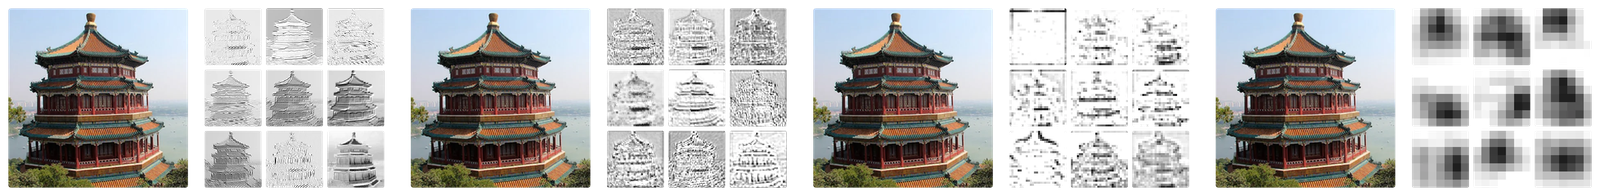

ResNet-50 trở lên dùng **bottleneck**: conv $1\times1$ thu hẹp số kênh, conv $3\times3$ làm việc ở chiều hẹp, rồi conv $1\times1$ mở rộng lại gấp 4. Ở `layer1`, block nhận và trả 256 kênh nhưng conv $3\times3$ chỉ chạy ở 64 kênh: $256\cdot64+64\cdot64\cdot9+64\cdot256=69\,632$ tham số, khớp dòng cuối của output. Hai conv $3\times3$ chạy thẳng ở 256 kênh cần $2\cdot256\cdot256\cdot9=1\,179\,648$, gấp gần 17 lần. Nhờ vậy ResNet-50 sâu gần gấp ba ResNet-18 mà chỉ nhiều tham số khoảng 2.2 lần.



Mọi conv trong ResNet đều có `bias=False`: BatchNorm ngay sau trừ mean theo từng kênh, nên hằng số bias cộng vào cả kênh bị trừ đi đúng bằng nó; việc dịch chuyển do $\beta$ của BatchNorm đảm nhận.

**Hỏi nhanh.** `Conv2d(64, 128, 3)` đứng ngay trước `BatchNorm2d(128)`. Để `bias=True` thì thêm bao nhiêu tham số, và chúng có tác dụng gì không?

- A. 128, nhưng không có tác dụng, vì BatchNorm trừ đi mean của từng kênh
- B. 128, và có tác dụng giúp BatchNorm hội tụ nhanh hơn
- C. 8192, nhưng không có tác dụng, vì BatchNorm trừ đi mean của từng kênh
- D. 8192, và có tác dụng giúp BatchNorm hội tụ nhanh hơn

<details><summary>Đáp án</summary>

A. 128, nhưng không có tác dụng, vì BatchNorm trừ đi mean của từng kênh

Mỗi kênh ra có một bias, tức 128. Bias cộng cùng một hằng số vào mọi vị trí của kênh, nên mean của kênh tăng đúng bằng nó, và BatchNorm trừ đi hết. Output không đổi dù bias là bao nhiêu, và gradient theo bias bằng 0. 8192 là $64\cdot 128$, số cặp kênh vào và ra, không phải số bias.

</details>

Mạng cho điện thoại như MobileNet tiết kiệm hơn nữa bằng **depthwise separable convolution**: conv $k\times k$ với `groups` bằng số kênh vào, mỗi bộ lọc chỉ đọc một kênh (depthwise), rồi conv $1\times1$ trộn các kênh (pointwise). Số tham số không bias đi từ $C_{\mathrm{out}}C_{\mathrm{in}}k^2$ xuống $C_{\mathrm{in}}k^2+C_{\mathrm{in}}C_{\mathrm{out}}$, nhỏ hơn gần $k^2$ lần khi $C_{\mathrm{out}}$ lớn; số phép nhân–cộng giảm cùng tỉ lệ. Ví dụ $3 \times 3$ từ 32 ra 64 kênh: 18 432 trọng số thường, còn $32 \cdot 9 + 32 \cdot 64 = 2336$ khi tách. Khi một model đã fine-tune chạy quá chậm trên điện thoại, thử kiến trúc nhẹ như MobileNet, ảnh đầu vào nhỏ hơn hoặc trọng số lượng tử hóa.

**Hỏi nhanh.** `nn.Conv2d(64, 64, 3, groups=64, bias=False).weight.shape` là gì?

- A. `(64, 64, 3, 3)`
- B. `(64, 1, 3, 3)`
- C. `(1, 64, 3, 3)`
- D. `(64, 3, 3)`

<details><summary>Đáp án</summary>

B. `(64, 1, 3, 3)`

Weight có shape $(C_{\mathrm{out}}, C_{\mathrm{in}}/\text{groups}, k, k)$: mỗi kênh ra chỉ đọc một kênh vào, tổng cộng 576 tham số thay vì $36\,864$ của conv thường. `(64, 64, 3, 3)` là conv thường. `(1, 64, 3, 3)` là một bộ lọc đọc cả 64 kênh. PyTorch luôn giữ đủ bốn chiều, nên không có `(64, 3, 3)`.

</details>

## CNN và ResNet đang giả định gì?

CNN và ResNet vẫn dựa vào tính cục bộ, chia sẻ trọng số và việc ghép nhiều mức chi tiết. Đường tắt giúp **tối ưu** mạng sâu; nó không thêm dữ liệu và không chống học thuộc. Train từ đầu ResNet-50 với hơn 25 triệu tham số trên vài trăm ảnh dễ học thuộc tập train, trong khi một CNN nhỏ có thể tổng quát tốt hơn. Trọng số pretrained trên ImageNet có ích khi đặc trưng chuyển được sang ảnh mới (bài 5.3); ảnh y khoa, camera hồng ngoại hay ký hiệu rất nhỏ khác xa ImageNet, nên phải so với baseline trên cùng validation trước khi tin.

Với ảnh nét phấn thật, thứ tự hợp lý là: TinyCNN làm baseline dễ debug, rồi một ResNet nhỏ train từ đầu hoặc encoder ResNet pretrained thay head (nếu đề cho phép), so tất cả trên cùng split và metric.

**Hỏi nhanh.** Có 300 ảnh, đề cấm dùng model pretrained. ResNet-50 train từ đầu đạt 100% trên train, 55% trên validation. Một CNN nhỏ đạt 85% trên train, 78% trên validation. Bước tiếp theo hợp lý là gì?

- A. Giữ mạng nhỏ, thêm augmentation và regularization
- B. Thêm residual vào ResNet-50 cho dễ tối ưu hơn nữa
- C. Chọn ResNet-50, vì accuracy trên train cao hơn
- D. Lên ResNet-101 để học được đặc trưng sâu hơn

<details><summary>Đáp án</summary>

A. Giữ mạng nhỏ, thêm augmentation và regularization

ResNet-50 đã có residual và đã tối ưu tốt, đạt 100% trên train. Khoảng cách 45 điểm giữa train và validation là học thuộc, thứ mà đường tắt không chữa được. Chọn theo accuracy trên train là chọn model học thuộc giỏi nhất. ResNet-101 thêm tham số, làm học thuộc nặng hơn. Mạng nhỏ đang tổng quát tốt hơn, và augmentation, weight decay hay dropout có thể kéo nó lên thêm.

</details>

## Khi đi thi

- **Chạy một batch qua model trước khi train.** In shape sau từng stage và đếm tham số; lỗi flatten, projection hay số kênh lộ ra trong vài giây thay vì sau một giờ GPU.
- **Baseline nhỏ trước, sâu sau.** Một CNN nhỏ hoặc ResNet-18 có checkpoint theo validation cho điểm nộp được sớm. Chỉ tăng độ sâu khi loss train còn cao; train tốt mà validation kém thì sâu hơn không chữa được.
- **Loss đứng ở mức đoán đều thì xem gradient.** In norm gradient của conv đầu và conv cuối; chênh nhau nhiều bậc thì thêm BatchNorm hoặc residual trước khi chỉnh learning rate.
- **Đọc luật về pretrained và kích thước ảnh.** Nếu đề cho phép, ResNet pretrained thay head thường mạnh hơn train từ đầu trên vài nghìn ảnh, với đúng preprocessing của checkpoint. Ảnh nhỏ cỡ vài chục pixel mỗi cạnh cần stem nhẹ hơn, vì stem ImageNet giảm cạnh 4 lần ngay từ đầu.
- **Đo thời gian trên đúng cấu hình nộp.** ResNet-50 có khoảng 25.6 triệu tham số, gấp 2.2 lần ResNet-18; chạy thử một epoch và một lượt suy luận trên batch thật trước khi chọn model.

## Tóm tắt

CNN ghép các feature map cục bộ thành nhãn ảnh qua activation, pooling và head; global average pooling cho head số đặc trưng cố định nhưng xóa phần lớn thông tin vị trí. Mạng plain sâu có thể không học nổi vì tín hiệu và gradient tắt dần qua nhiều lớp. Residual $y=x+F(x)$ giữ một đường đi thẳng cho gradient, BatchNorm giữ thang của tín hiệu, và hai nhánh phải cùng shape (projection khi đổi kênh hay stride). ResNet ghép các block ấy thành bốn stage, dùng bottleneck và conv không bias trước BatchNorm để sâu mà vẫn gọn. Một training loop chạy được, loss giảm và validation hợp lệ là ba bằng chứng bổ sung cho nhau.

## Kiểm tra cuối bài

**Câu 1.** Trong TinyCNN, mỗi ô của feature map sau conv thứ hai, có shape `(N, 8, 6, 6)`, chịu ảnh hưởng của một vùng ảnh đầu vào rộng bao nhiêu?

- A. $5\times 5$
- B. $6\times 6$
- C. $8\times 8$
- D. $12\times 12$

<details><summary>Đáp án</summary>

C. $8\times 8$

Conv $3\times 3$ đầu cho mỗi ô một vùng 3 ô. MaxPool 2 gộp hai ô liền nhau thành một vùng 4 ô, và hai ô kề nhau sau pooling cách nhau 2 pixel. Conv $3\times 3$ sau pooling đọc ba ô cách nhau 2, nên vùng là $4 + 2\cdot 2 = 8$. $5\times 5$ là của hai conv $3\times 3$ liền nhau không có pooling. $6\times 6$ là nhầm với kích thước feature map. $12\times 12$ là cả ảnh, chỉ đạt được sau global average pooling. Một nét dài 8 ô vừa nằm trọn trong một vùng.

</details>

**Câu 2.** Trên ảnh vật thể $224\times 224$, một đội so một CNN chỉ có hai lớp conv $3\times 3$ liền nhau với ResNet-18, cùng dữ liệu và cùng số epoch, và ResNet-18 có validation cao hơn hẳn. Lý do chính là gì?

- A. Mạng sâu hơn luôn chạy nhanh hơn
- B. Mạng sâu ghép dần từ cạnh thành kết cấu rồi thành vật thể
- C. Mạng sâu hơn có ít tham số hơn
- D. Mạng sâu hơn dễ train hơn mạng nông

<details><summary>Đáp án</summary>

B. Mạng sâu ghép dần từ cạnh thành kết cấu rồi thành vật thể

Hai conv $3\times 3$ liền nhau chỉ nhìn một vùng $5\times 5$ của ảnh 224 pixel, đủ thấy cạnh nhưng không thấy hình dạng. Mạng sâu có receptive field lớn dần qua từng stage, nên học được đặc trưng theo tầng bậc: lớp đầu bắt cạnh, lớp giữa ghép thành kết cấu và bộ phận, lớp cuối đọc ra vật thể. ResNet-18 chạy chậm hơn, và có khoảng 11.7 triệu tham số, nhiều hơn hẳn. Mạng sâu cũng khó train hơn mạng nông; đó chính là lý do cần residual.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 206](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=75)

</details>

**Câu 3.** TinyCNN được train trên ảnh $12\times 12$. Một bản khác thay `AdaptiveAvgPool2d(1)` bằng `Flatten()` và head `Linear(288, 2)`. Đưa ảnh test $16\times 16$ vào hai model thì sao?

- A. Cả hai đều chạy và ra `(N, 2)`
- B. Cả hai đều báo lỗi shape
- C. TinyCNN báo lỗi, còn bản Flatten chạy được
- D. TinyCNN chạy được, còn bản Flatten báo lỗi

<details><summary>Đáp án</summary>

D. TinyCNN chạy được, còn bản Flatten báo lỗi

Ảnh $16\times 16$ qua pooling còn $8\times 8$, feature map có shape `(N, 8, 8, 8)`. Global average pooling lấy trung bình mỗi kênh nên vẫn ra 8 số. Flatten ra $8\cdot 8\cdot 8 = 512$ số, không khớp với 288 của `Linear`, và PyTorch báo `mat1 and mat2 shapes cannot be multiplied`. Chạy được chưa có nghĩa là dự đoán đúng: dữ liệu khác kích thước vẫn phải được kiểm trên validation có cùng kích thước ấy.

</details>

**Câu 4.** Bảng cấu hình ResNet-152 có conv $3\times 3$, BatchNorm, pooling và phép cộng đường tắt. Thành phần nào là đóng góp riêng của ResNet, giúp train được mạng hơn 100 lớp?

- A. Đường tắt cộng đầu vào vào đầu ra của mỗi block
- B. BatchNorm đặt sau mỗi convolution
- C. Bộ lọc $5\times 5$ thay cho $3\times 3$ trong block
- D. Nhiều lớp pooling hơn giữa các stage

<details><summary>Đáp án</summary>

A. Đường tắt cộng đầu vào vào đầu ra của mỗi block

Đường tắt là ý tưởng mới của ResNet: mỗi block chỉ học phần sửa $F(x)$, và gradient có lối đi thẳng qua phép cộng. BatchNorm có từ trước ResNet (Ioffe và Szegedy, 2015). ResNet dùng lại nó, và chính bài báo ResNet cho thấy mạng thường 34 lớp, dù có BatchNorm, vẫn train kém hơn mạng 18 lớp. Các block của ResNet giữ bộ lọc $3\times 3$ như VGG. Thêm pooling chỉ làm ảnh nhỏ đi, không giúp gradient đi qua 100 lớp.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 216](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=78)

</details>

**Câu 5.** Một chuỗi 10 neuron một chiều có đường tắt: $o_i = o_{i-1} + \sigma(w_io_{i-1} + b_i)$, với $o_0 = x$, $\sigma$ là sigmoid và mọi $w_i = 1$. Đạo hàm $\partial o_{10}/\partial x$ nằm trong khoảng nào?

- A. $(0,\ 4^{-10}]$
- B. $[4^{-10},\ 1]$
- C. Đúng bằng $1$
- D. $[1,\ 1.25^{10}]$

<details><summary>Đáp án</summary>

D. $[1,\ 1.25^{10}]$

Mỗi lớp cho $\partial o_i/\partial o_{i-1} = 1 + w_i\sigma'(s_i) = 1 + \sigma'(s_i)$, với $0 < \sigma' \le 1/4$, nên mỗi thừa số nằm trong $(1,\ 1.25]$. Tích của mười thừa số nằm giữa 1 và $1.25^{10} \approx 9.31$. Bỏ đường tắt đi, cùng chuỗi ấy chỉ còn tích các $\sigma'(s_i) \le 1/4$, với cận trên $4^{-10} \approx 10^{-6}$: đó là vanishing gradient. “Đúng bằng 1” là chỉ tính đường đồng nhất, bỏ qua phần đóng góp của các nhánh.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q4.5](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=20)

</details>

**Câu 6.** Một đội train hai CNN thường, không có đường tắt, cùng dữ liệu, cùng BatchNorm và khởi tạo He. Mạng 20 lớp có lỗi 6% trên train, 9% trên validation. Mạng 56 lớp có lỗi 11% trên train, 14% trên validation. Chẩn đoán và cách sửa nào hợp lý?

- A. Mạng sâu overfit, nên thêm dropout cho mạng 56 lớp
- B. Gradient quá lớn, nên clip độ lớn gradient về 1
- C. Mạng sâu khó tối ưu, nên thêm residual connection
- D. Mạng 56 lớp thừa tham số, nên giảm số kênh

<details><summary>Đáp án</summary>

C. Mạng sâu khó tối ưu, nên thêm residual connection

Mạng 56 lớp tệ hơn ngay trên train, nên không phải overfit; overfit thì lỗi train thấp, validation cao. Nó biểu diễn được mọi thứ mạng 20 lớp làm được, nên vấn đề nằm ở việc tối ưu. Residual cho gradient một lối đi thẳng qua các block, và giúp mỗi block dễ học gần phép đồng nhất. Clip gradient chữa gradient bùng nổ, mà ở đây không có dấu hiệu loss nổ. Giảm số kênh làm mạng yếu đi mà không gỡ được khó khăn của việc tối ưu.
Phỏng theo: [NOAI 2025 Singapore · Phần 1 · Câu 9](https://learn.aisingapore.org/wp-content/uploads/2025/10/NOAI-2025-MCQ-Assessment-Questions.pdf#page=2)

</details>

**Câu 7.** Mỗi block tính $y = x + F(x)$, không có ReLU sau phép cộng, và nhánh $F$ là conv, ReLU, rồi conv. Khởi tạo conv cuối của mọi nhánh bằng 0, cả weight lẫn bias. Ở bước train đầu tiên, mạng 50 block hoạt động thế nào?

- A. Không học được, vì mọi gradient trong nhánh đều bằng 0
- B. Ra toàn số 0, nên không tính được loss
- C. Như thể bỏ hết các block, và mọi conv đều nhận gradient ngay
- D. Như thể bỏ hết các block, và conv cuối vẫn nhận được gradient

<details><summary>Đáp án</summary>

D. Như thể bỏ hết các block, và conv cuối vẫn nhận được gradient

$F(x) = 0$ nên mỗi block trả về nguyên $x$: mạng sâu bắt đầu như một mạng nông, tín hiệu và gradient đi thẳng qua 50 block, và đầu ra là $x$ chứ không phải 0. Gradient theo weight của conv cuối là gradient ở đầu ra nhân với đầu vào của nó, tức $\mathrm{ReLU}(\text{conv đầu}(x))$, khác 0. Gradient về conv đầu phải đi qua weight của conv cuối, đang bằng 0, nên ở bước đầu nó bằng 0, sang bước sau mới có. torchvision có tùy chọn `zero_init_residual`, làm cùng ý tưởng ấy với $\gamma$ của BatchNorm cuối nhánh.

</details>

**Câu 8.** Đưa ảnh $32\times 32$, cỡ của CIFAR-10, vào ResNet-18 của torchvision, giữ nguyên phần stem cho ImageNet. Output của `layer4` có kích thước không gian bao nhiêu?

- A. $1\times 1$
- B. $2\times 2$
- C. $4\times 4$
- D. $7\times 7$

<details><summary>Đáp án</summary>

A. $1\times 1$

Conv stem stride 2 đưa $32$ xuống $16$. Max pooling stride 2 đưa $16$ xuống $8$. `layer1` giữ 8. `layer2`, `layer3`, `layer4` mỗi stage chia đôi: $8 \to 4 \to 2 \to 1$. Tổng cộng giảm 32 lần, như $224 \to 7$ trong code của bài; $7\times 7$ là chép đúng con số ấy. `layer3` và `layer4` chỉ còn $2\times 2$ rồi $1\times 1$ vị trí cho conv $3\times 3$ làm việc, nên bản ResNet cho CIFAR thường thay stem bằng conv $3\times 3$ stride 1 và bỏ max pooling.

</details>

**Câu 9.** Thay một conv $3\times 3$ thường, từ 64 lên 128 kênh, bằng depthwise separable: depthwise $3\times 3$ trên từng kênh, tức `groups=64`, rồi pointwise $1\times 1$ lên 128 kênh. Mọi conv đều không có bias. Số tham số trước và sau là bao nhiêu?

- A. $73\,728$ và $1152$
- B. $73\,728$ và $8768$
- C. $73\,728$ và $45\,056$
- D. $8192$ và $8768$

<details><summary>Đáp án</summary>

B. $73\,728$ và $8768$

Conv thường có $128\cdot 64\cdot 9 = 73\,728$ tham số. Depthwise có $64\cdot 9 = 576$, pointwise có $64\cdot 128 = 8192$, tổng cộng $8768$, ít hơn khoảng 8.4 lần, và số phép nhân cộng tại mỗi vị trí cũng giảm theo cùng tỉ lệ. $45\,056$ là tính depthwise như một conv đầy đủ từ 64 sang 64. $1152$ là conv `groups=64` đi thẳng lên 128 kênh mà thiếu bước pointwise trộn các kênh. $8192$ là quên $3^2$ của conv thường.
Phỏng theo: [NOAI 2025 Singapore · Phần 1 · Câu 14](https://learn.aisingapore.org/wp-content/uploads/2025/10/NOAI-2025-MCQ-Assessment-Questions.pdf#page=3)

</details>

**Câu 10.** Đề cho 4000 ảnh $64\times 64$, 10 lớp, chấm bằng accuracy, cấm dùng model pretrained, ngân sách 3 giờ GPU. Kế hoạch nào hợp lý nhất?

- A. Train một ResNet nhỏ từ đầu, giữ checkpoint theo validation, rồi tăng dần
- B. Train ResNet-152 từ đầu suốt 3 giờ, nộp checkpoint cuối cùng
- C. Nạp ResNet-50 pretrained trên ImageNet, vì thường cho điểm cao nhất
- D. Gộp validation vào train ngay từ đầu cho có thêm dữ liệu

<details><summary>Đáp án</summary>

A. Train một ResNet nhỏ từ đầu, giữ checkpoint theo validation, rồi tăng dần

Mạng nhỏ cho ra một bản nộp được chỉ sau vài phút, và checkpoint theo validation giữ model tốt nhất phòng khi hết giờ. Còn thời gian thì mới tăng độ sâu hay thêm augmentation. ResNet-152 có hơn 60 triệu tham số, trên 4000 ảnh rất dễ học thuộc, và checkpoint cuối chưa chắc là tốt nhất. Dùng model pretrained là trái luật đề. Bỏ validation từ đầu thì không còn gì để chọn checkpoint hay so các cấu hình. Gộp lại để train lần cuối chỉ hợp lý sau khi đã chọn xong cấu hình.

</details>

## Đọc thêm

- He và cộng sự — [Deep Residual Learning for Image Recognition](https://arxiv.org/abs/1512.03385): đọc vấn đề tối ưu khi tăng chiều sâu và ý tưởng học residual.
- [PyTorch — Defining a Neural Network](https://docs.pytorch.org/tutorials/recipes/recipes/defining_a_neural_network.html): đối chiếu cách tổ chức `nn.Module` và `forward`.
- Howard và cộng sự — [MobileNets](https://arxiv.org/abs/1704.04861): depthwise separable convolution và cách đổi độ chính xác lấy tốc độ trên thiết bị nhỏ.
- [Dive into Deep Learning — ResNet](https://d2l.ai/chapter_convolutional-modern/resnet.html): xem biến thể có projection và cấu trúc nhiều stage; block minh họa của bài nhỏ hơn mạng trong sách.

Nguồn ảnh: ảnh tháp là ảnh mẫu `china.jpg` kèm scikit-learn (danielbuechele, Flickr, CC BY 2.0).